In [9]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.1 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 3. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.7 * nS 
g_AMPA_rec_E = 5.7 * nS 
g_AMPA_ext_I = 5.7 * nS
g_AMPA_rec_I = 5.7 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0


tau_HSP = 100*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3


kill_mask = np.ones(100, dtype=np.float32)
#kill_mask[range(40,47)]=0 #yes
#kill_mask[np.array([range(40,47),range(21,28)]).flatten()]=0 #yes
kill_mask[np.array([range(42,47),range(32,37)]).flatten()]=0
pen_idx = np.concatenate([range(21,28),[31,38,41,48],range(51,58)])
far_idx = np.concatenate([range(1,18),range(71,99)])
index_penumbra=np.concatenate([range(21,28),[31,38,41,48],range(51,58)])
core_idx = np.where(kill_mask == 0)[0]          


def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10 
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * k_AMPA_E_hsp  * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E * k_GABA_E_hsp * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
                - (k_AMPA_E_hsp - 0.1) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

    dk_GABA_E_hsp/dt = (-(k_GABA_E_hsp - 0.1) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_int_GABA_E
                + (1 - k_GABA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * 0.3 * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * 0.3 * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz


    dy_act / dt = -y_act / tau_active : 1
    '''


    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.k_AMPA_E_hsp = 0.3  
    P_E.k_GABA_E_hsp = 0.3  
    P_E.tau_ins_AMPA_E = tau_ins_AMPA   #50'000
    P_E.tau_int_AMPA_E = tau_int_AMPA   #5'000
    P_E.tau_ins_GABA_E = tau_ins_GABA   
    P_E.tau_int_GABA_E = tau_int_GABA  

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L


    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    
    C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
        s_AMPA_ext += w  
        ''', method='euler', name='PG_E')
    C_PG_E.connect(j='i')  

    N_pen = len(index_penumbra)
    pg_pen = PoissonGroup(N_pen, rates=0*Hz, name='pen_inp')

    C_PEN_E = Synapses(pg_pen, P_E, model='w:1', on_pre='s_AMPA_ext += w', method='euler', name='PEN_E')
    C_PEN_E.connect(i=np.arange(N_pen), j=index_penumbra)
    C_PEN_E.w[:] = 1.0


    C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
        s_AMPA += w  
        ''', method='euler', name='E_E')
    recurrent_radius = 2
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)
    C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
    s_AMPA += w
    ''', method='euler', name='E_I') #        x_postE_post += 1.0 
    C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
    for inh_idx, (ix, iy) in enumerate(inh_positions):
        for ex_y in range(n_output_rows):
            for ex_x in range(n_output_columns):
                if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                    exc_idx = ex_y * n_output_columns + ex_x
                    C_I_E.connect(i=inh_idx, j=exc_idx)
                    C_E_I.connect(i=exc_idx, j=inh_idx)
    C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
    for iy in range(n_inh_rows):
        for ix in range(n_inh_cols):
            post = iy * n_inh_cols + ix
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    if dx == 0 and dy == 0:
                        continue
                    x2, y2 = ix + dx, iy + dy
                    if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                        pre = y2 * n_inh_cols + x2
                        C_I_I.connect(i=pre, j=post)



    C_PG_E.w[:] = 1.2 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
    C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
    C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
    C_E_I.w[:] = 0.6#np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
    C_E_E.w[:] = np.clip(np.random.normal(loc=0.44, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    rate_core = NeuronGroup(1, 'r_core : Hz', method='euler', name='rate_core')
    rate_pen  = NeuronGroup(1, 'r_pen  : Hz', method='euler', name='rate_pen')
    rate_far  = NeuronGroup(1, 'r_far  : Hz', method='euler', name='rate_far')
    # Core
    C_r_core = Synapses(
        P_E, rate_core,
        model=''' N_core : 1
        r_core_post = r_est_pre / N_core : Hz (summed)''',
        method='euler',
        name='C_r_core'
    )
    C_r_core.connect(i=core_idx, j=0)
    C_r_core.N_core = len(core_idx)
    # Penumbra
    C_r_pen = Synapses(
        P_E, rate_pen,
        model='''N_pen : 1
        r_pen_post = r_est_pre / N_pen : Hz (summed)''',
        method='euler',
        name='C_r_pen'
    )
    C_r_pen.connect(i=pen_idx, j=0)
    C_r_pen.N_pen= len(pen_idx)
    # Far
    C_r_far = Synapses(
        P_E, rate_far,
        model='''N_far : 1
        r_far_post = r_est_pre / N_far : Hz (summed)''',
        method='euler',
        name='C_r_far'
    )
    C_r_far.connect(i=far_idx, j=0)
    C_r_far.N_far=len(far_idx)
    
    rate_core_mon = StateMonitor(rate_core, 'r_core', record=True, dt=record_dt, name='rate_core_mon')
    rate_pen_mon  = StateMonitor(rate_pen,  'r_pen',  record=True, dt=record_dt, name='rate_pen_mon')
    rate_far_mon  = StateMonitor(rate_far,  'r_far',  record=True, dt=record_dt, name='rate_far_mon')

    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'k_AMPA_E_hsp', record=True, dt=record_dt, name='k_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'k_GABA_E_hsp', record=True, dt=record_dt, name='k_GABA_E_hsp')

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net

def add_penumbra_pulses(net, pen_base=0*Hz, pen_amp=10*Hz, T_on=2*second, T_off=8*second):
    period = T_on + T_off

    @network_operation(dt=10*second)
    def pen_pulse_op():
        t = defaultclock.t
        phase = (t % period)
        net['pen_inp'].rates = (pen_amp if phase < T_on else pen_base)

    net.add(pen_pulse_op)

def show_rand_rate(net, show_time = 100*second):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=0, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')



def run_sim(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,show_time = 100*second,pulse_pen=True):
    net = build_network(tau_ins_AMPA=tau_ins_AMPA,tau_int_AMPA=tau_int_AMPA,tau_ins_GABA=tau_ins_GABA,tau_int_GABA=tau_int_GABA)
    if pulse_pen:
        add_penumbra_pulses(net, pen_base=0*Hz, pen_amp=20*Hz, T_on=20*second, T_off=40*second)
    show_rand_rate(net,show_time=show_time)
    return net



no penumbra pulse

INFO:root:creating /tmp/brian_flag_test_lmln_l0_/tmp
INFO:root:creating /tmp/brian_flag_test_lmln_l0_/tmp/brian_flag_test_lmln_l0_
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_lmln_l0_/flag_test.cpp -o /tmp/brian_flag_test_lmln_l0_/tmp/brian_flag_test_lmln_l0_/flag_test.o -w
INFO:root:creating /tmp/brian_flag_test_mvs4fsn6/tmp
INFO:root:creating /tmp/brian_flag_test_mvs4fsn6/tmp/brian_flag_test_mvs4fsn6
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_mvs4fsn6/flag_test.cpp -o /tmp/brian_flag_test_mvs4fsn6/tmp/brian_flag_test_mvs4fsn6/flag_test.o -O3
INFO:root:creating /tmp/brian_flag_test_r1czt71o/tmp
INFO:root:creating /tmp/brian_flag_test_r1czt71o/tmp/brian_flag_test_r1czt71o
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_r1czt71o/flag_test.cpp -o /tmp/brian_flag_test_r1

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([40., 40., 40., ..., 40., 40., 40.]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'rates' is an internal variable of group 'pen_inp', but also exists in the run namespace with the value array([40., 40., 40., ..., 40., 40., 40.]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 20. ks
110.221 s (0%) simulated in 10s, estimated 30m 5s remaining.
206.962 s (1%) simulated in 20s, estimated 31m 53s remaining.
0.320865 ks (1%) simulated in 30s, estimated 30m 40s remaining.
0.429726 ks (2%) simulated in 40s, estimated 30m 22s remaining.
0.525433 ks (2%) simulated in 50s, estimated 30m 53s remaining.
0.63663 ks (3%) simulated in 1m 0s, estimated 30m 25s remaining.
0.751262 ks (3%) simulated in 1m 10s, estimated 29m 54s remaining.
0.850813 ks (4%) simulated in 1m 20s, estimated 30m 1s remaining.
0.965424 ks (4%) simulated in 1m 30s, estimated 29m 34s remaining.
1.072825 ks (5%) simulated in 1m 40s, estimated 29m 24s remaining.
1.183552 ks (5%) simulated in 1m 50s, estimated 29m 9s remaining.
1.273243 ks (6%) simulated in 2m 0s, estimated 29m 25s remaining.
1.388511 ks (6%) simulated in 2m 10s, estimated 29m 3s remaining.
1.502067 ks (7%) simulated in 2m 20s, estimated 28m 44s remaining.
1.587315 ks (7%) simulated in 2m 

WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



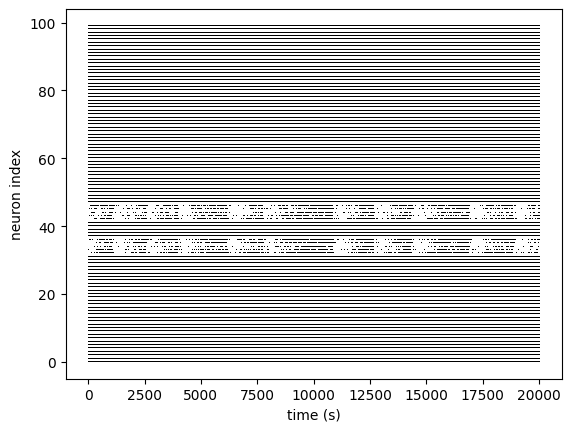

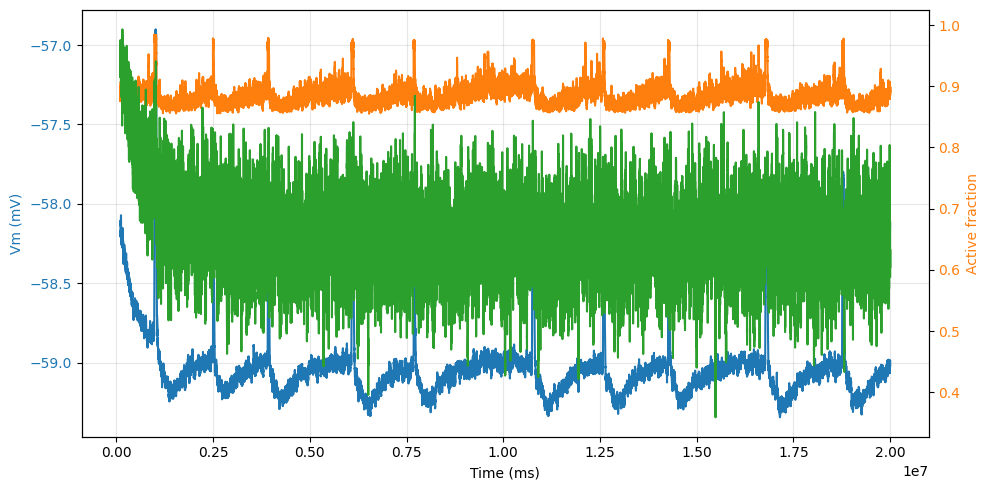

In [2]:
start_scope()
defaultclock.dt = 1000 * us
net = run_sim(tau_ins_AMPA=500*second,
              tau_int_AMPA=500*second,
              tau_ins_GABA=500*second,
              tau_int_GABA=500*second,
              show_time=20000*second,
              pulse_pen=False)


V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')


fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

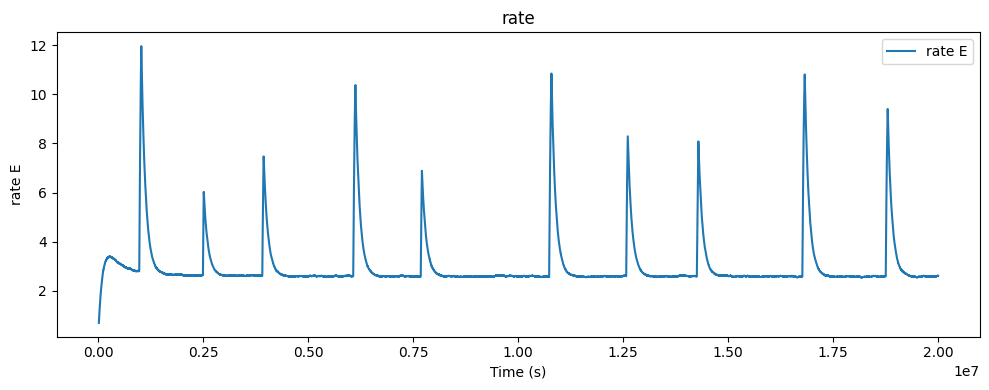

In [3]:
r_est_E_no_pulse = net['rate_pop_mon_E']  
r_est_I = net['rate_pop_mon_I']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E_no_pulse.t[100:]/ms, r_est_E_no_pulse.r_pop_E[0,100:]/Hz, color='tab:blue', label='rate E')
#plt.plot(r_est_I.t[500:]/ms, r_est_I.r_pop_I[0,500:]/Hz, color='tab:green', label='rate I')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

With Pulse

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Starting simulation at t=0. s for a duration of 20. ks
119.818 s (0%) simulated in 10s, estimated 27m 39s remaining.
230.873 s (1%) simulated in 20s, estimated 28m 33s remaining.
0.332844 ks (1%) simulated in 30s, estimated 29m 33s remaining.
0.453834 ks (2%) simulated in 40s, estimated 28m 43s remaining.
0.576566 ks (2%) simulated in 50s, estimated 28m 4s remaining.
0.694977 ks (3%) simulated in 1m 0s, estimated 27m 47s remaining.
0.80087 ks (4%) simulated in 1m 10s, estimated 27m 58s remaining.
0.92307 ks (4%) simulated in 1m 20s, estimated 27m 33s remaining.
1.043991 ks (5%) simulated in 1m 30s, estimated 27m 14s remaining.
1.14719 ks (5%) simulated in 1m 40s, estimated 27m 23s remaining.
1.268229 ks (6%) simulated in 1m 50s, estimated 27m 5s remaining.
1.385853 ks (6%) simulated in 2m 0s, estimated 26m 52s remaining.
1.495854 ks (7%) simulated in 2m 10s, estimated 26m 58s remaining.
1.615772 ks (8%) 

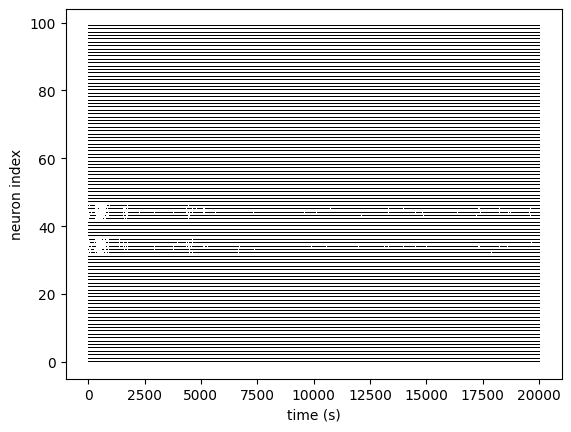

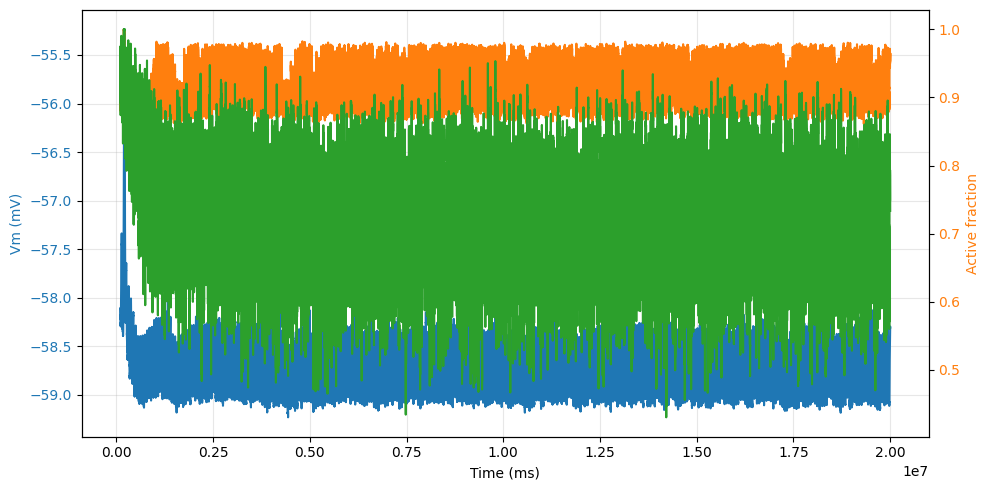

In [10]:
start_scope()
defaultclock.dt = 1000 * us
net = run_sim(tau_ins_AMPA=500*second,
              tau_int_AMPA=500*second,
              tau_ins_GABA=500*second,
              tau_int_GABA=500*second,
              show_time=20000*second,
              pulse_pen=True)


V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')


fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

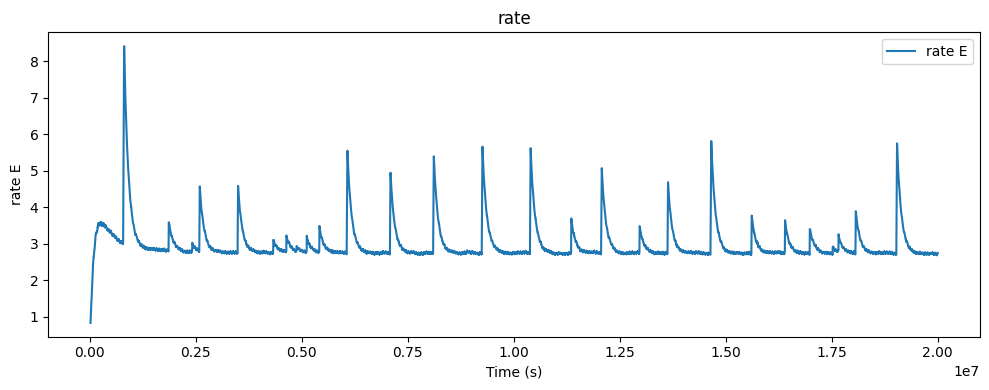

In [6]:
r_est_E_pulse_10 = net['rate_pop_mon_E']  
#r_est_I = net['rate_pop_mon_I']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E_pulse_10.t[100:]/ms, r_est_E_pulse_10.r_pop_E[0,100:]/Hz, color='tab:blue', label='rate E')
#plt.plot(r_est_I.t[500:]/ms, r_est_I.r_pop_I[0,500:]/Hz, color='tab:green', label='rate I')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

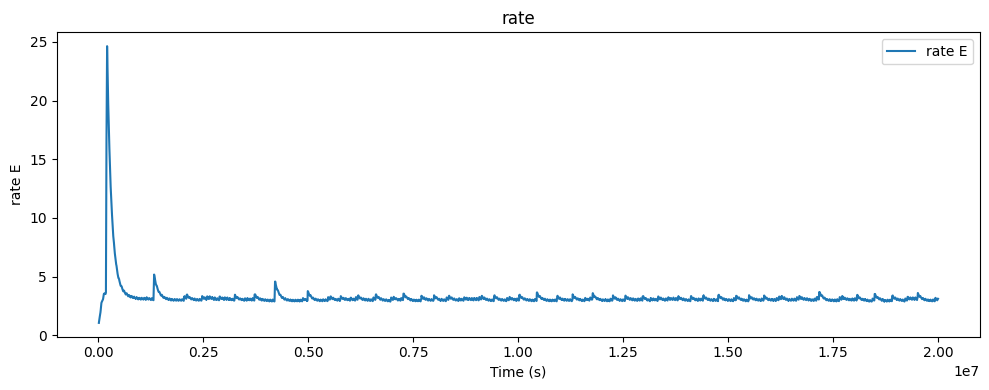

In [11]:
r_est_E_pulse_20 = net['rate_pop_mon_E']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E_pulse_20.t[100:]/ms, r_est_E_pulse_20.r_pop_E[0,100:]/Hz, color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

Plot both

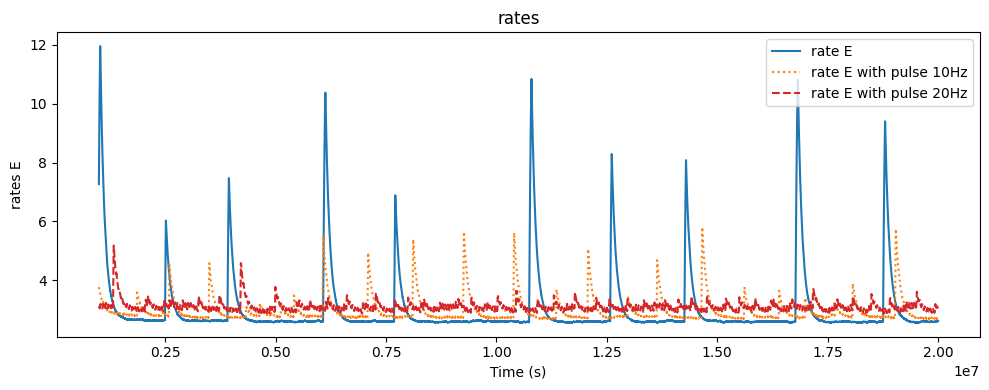

In [22]:
plt.figure(figsize=(10, 4))
plt.plot(r_est_E_no_pulse.t[5000:]/ms, r_est_E_no_pulse.r_pop_E[0,5000:]/Hz, color='tab:blue', label='rate E',linestyle='-')
plt.plot(r_est_E_pulse_10.t[5000:]/ms, r_est_E_pulse_10.r_pop_E[0,5000:]/Hz, color='tab:orange', label='rate E with pulse 10Hz',linestyle=':')
plt.plot(r_est_E_pulse_20.t[5000:]/ms, r_est_E_pulse_20.r_pop_E[0,5000:]/Hz, color='tab:red', label='rate E with pulse 20Hz',linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('rates E')
plt.title('rates')
plt.legend(loc=1)
plt.tight_layout()

all no pulse

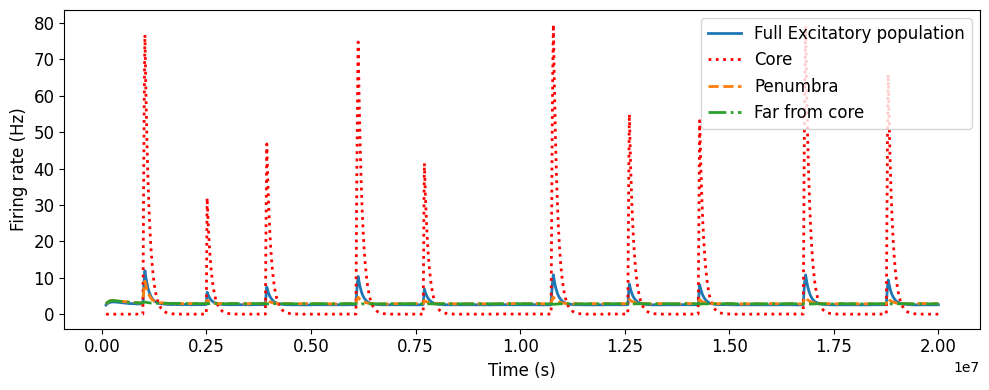

In [4]:
r_est_E = net['rate_pop_mon_E']  
r_est_E_core = net['rate_core_mon']  
r_est_E_pen = net['rate_pen_mon']  
r_est_E_far = net['rate_far_mon']  


plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[500:]/ms, r_est_E.r_pop_E[0,500:]/Hz, color='tab:blue',linewidth=2, label='Full Excitatory population')
plt.plot(r_est_E_core.t[500:]/ms, r_est_E_core.r_core[0,500:]/Hz, color='red',linewidth=2,linestyle=':', label='Core')
plt.plot(r_est_E_pen.t[500:]/ms, r_est_E_pen.r_pen[0,500:]/Hz, color='tab:orange',linewidth=2,linestyle='--', label='Penumbra')
plt.plot(r_est_E_far.t[500:]/ms, r_est_E_far.r_far[0,500:]/Hz, color='tab:green',linewidth=2,linestyle='-.', label='Far from core')
plt.xlabel('Time (s)', fontsize =12)
plt.ylabel('Firing rate (Hz)',fontsize =12)
plt.tick_params(axis='both', labelsize=12)
plt.legend(loc=1,fontsize=12)
plt.tight_layout()

all pulse 10Hz

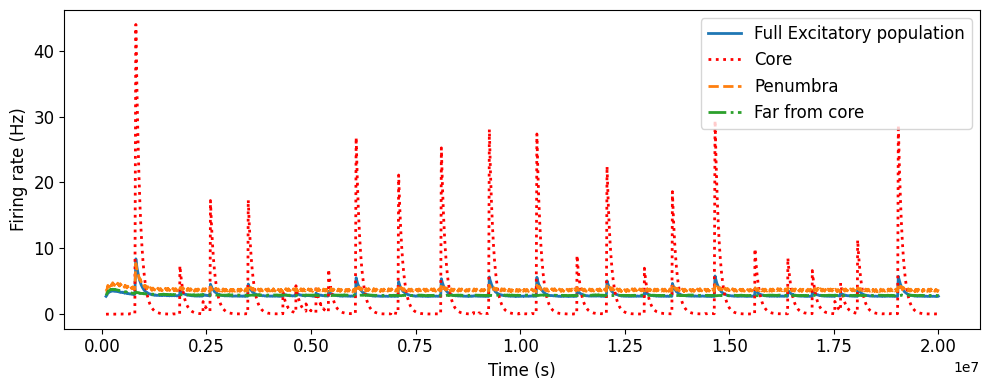

In [8]:
r_est_E = net['rate_pop_mon_E']  
r_est_E_core = net['rate_core_mon']  
r_est_E_pen = net['rate_pen_mon']  
r_est_E_far = net['rate_far_mon']  


plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[500:]/ms, r_est_E.r_pop_E[0,500:]/Hz, color='tab:blue',linewidth=2, label='Full Excitatory population')
plt.plot(r_est_E_core.t[500:]/ms, r_est_E_core.r_core[0,500:]/Hz, color='red',linewidth=2,linestyle=':', label='Core')
plt.plot(r_est_E_pen.t[500:]/ms, r_est_E_pen.r_pen[0,500:]/Hz, color='tab:orange',linewidth=2,linestyle='--', label='Penumbra')
plt.plot(r_est_E_far.t[500:]/ms, r_est_E_far.r_far[0,500:]/Hz, color='tab:green',linewidth=2,linestyle='-.', label='Far from core')
plt.xlabel('Time (s)', fontsize =12)
plt.ylabel('Firing rate (Hz)',fontsize =12)
plt.tick_params(axis='both', labelsize=12)
plt.legend(loc=1,fontsize=12)
plt.tight_layout()

all pulse 20Hz

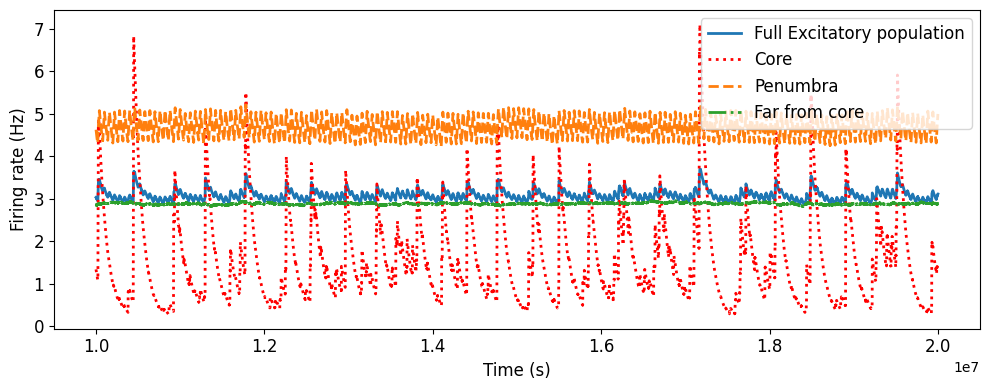

In [20]:
r_est_E = net['rate_pop_mon_E']  
r_est_E_core = net['rate_core_mon']  
r_est_E_pen = net['rate_pen_mon']  
r_est_E_far = net['rate_far_mon']  


plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[50000:]/ms, r_est_E.r_pop_E[0,50000:]/Hz, color='tab:blue',linewidth=2, label='Full Excitatory population')
plt.plot(r_est_E_core.t[50000:]/ms, r_est_E_core.r_core[0,50000:]/Hz, color='red',linewidth=2,linestyle=':', label='Core')
plt.plot(r_est_E_pen.t[50000:]/ms, r_est_E_pen.r_pen[0,50000:]/Hz, color='tab:orange',linewidth=2,linestyle='--', label='Penumbra')
plt.plot(r_est_E_far.t[50000:]/ms, r_est_E_far.r_far[0,50000:]/Hz, color='tab:green',linewidth=2,linestyle='-.', label='Far from core')
plt.xlabel('Time (s)', fontsize =12)
plt.ylabel('Firing rate (Hz)',fontsize =12)
plt.tick_params(axis='both', labelsize=12)
plt.legend(loc=1,fontsize=12)
plt.tight_layout()